In [1]:
import numpy as np
from detector import Detector
from source import Source
import matplotlib.pyplot as plt

# Создаем 1 детектор и 1 источник
start_point = np.array([0, 0, 0])

detector_1 = Detector(2, 40, 0.1, 0.5)
detector_1.place_photomultipliers()

source = Source(10**4, start_point)



In [2]:
# Начинаем генерацию 1000 семплов
Q_full = []
for i in range(1000):
    photon_directions = source.generate_directions(1) # создали фотоны
    cross_points = detector_1.find_cross_point(source.position, photon_directions) # посчитали точки пересечения
    pm_points = detector_1.find_photomultiplier(cross_points) # нашли нужные фэу
    hits = np.sum(pm_points != -1) # посчитали попадания в фэу
    detections = detector_1.generate_photo_electrons(hits) # собрали полный заряд
    Q_full.append(detections)

Q_full = np.array(Q_full)

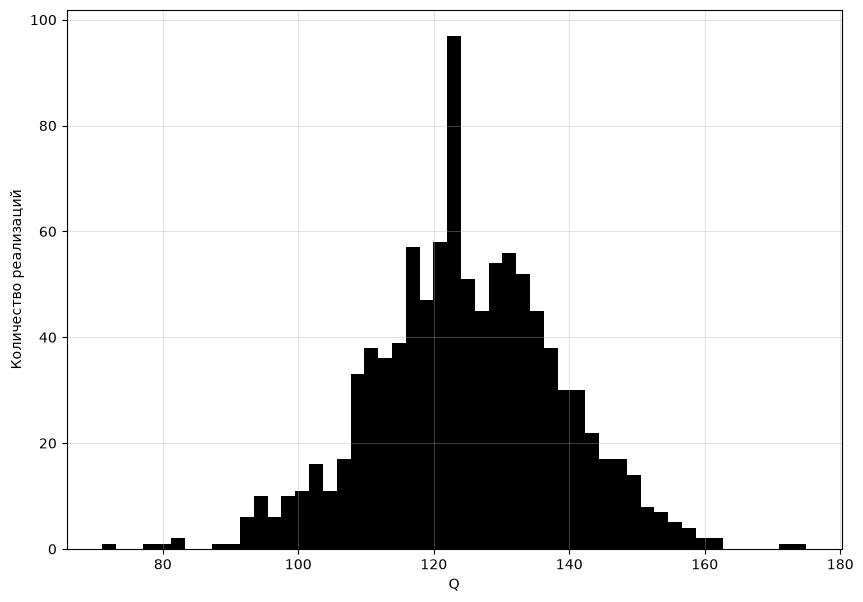

In [3]:
# строим гистограмму распределения Q

plt.figure(figsize=(10, 7))
plt.subplot(111)
plt.hist(Q_full, bins=51, color='k')
plt.xlabel("Q")
plt.ylabel("Количество реализаций")
plt.grid()

plt.show()


In [4]:
# моделирование с разными энергиями
energy_list = [0.2, 0.5, 0.7, 1.5, 2.0, 3.0]

Q_very_full = [[] for _ in energy_list]
for n, E in enumerate(energy_list):
    for i in range(1000):
        photon_directions = source.generate_directions(E) # создали фотоны
        cross_points = detector_1.find_cross_point(source.position, photon_directions) # посчитали точки пересечения
        pm_points = detector_1.find_photomultiplier(cross_points) # нашли нужные фэу
        hits = np.sum(pm_points != -1) # посчитали попадания в фэу
        detections = detector_1.generate_photo_electrons(hits) # собрали полный заряд
        Q_very_full[n].append(detections)

Q_very_full = np.array(Q_very_full) # заворачиваем в массивы


(6, 1000)


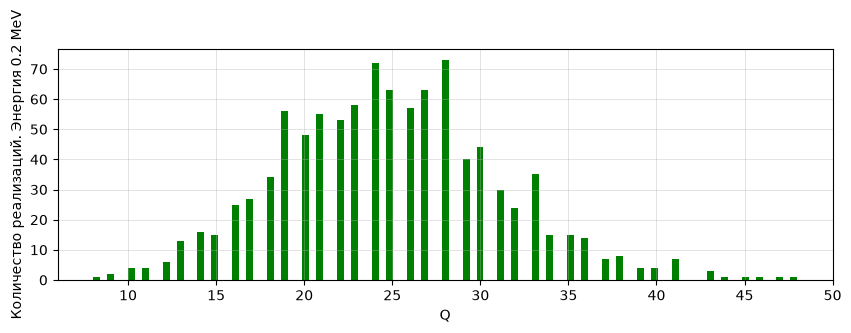

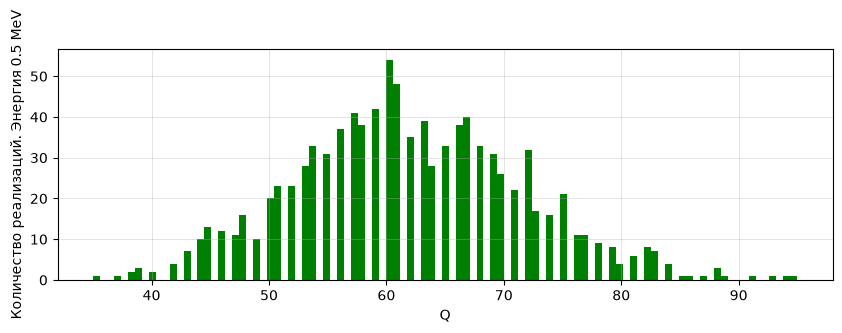

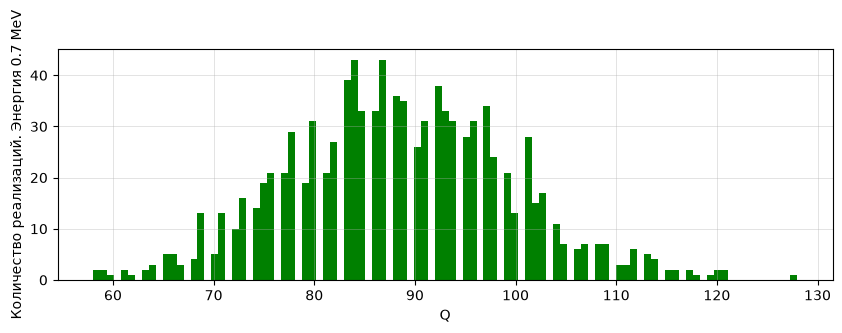

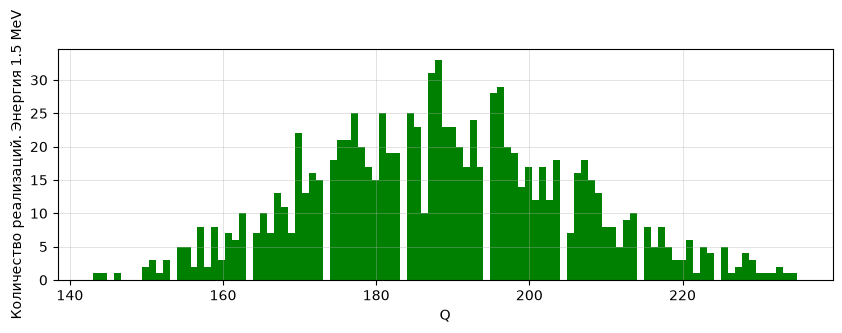

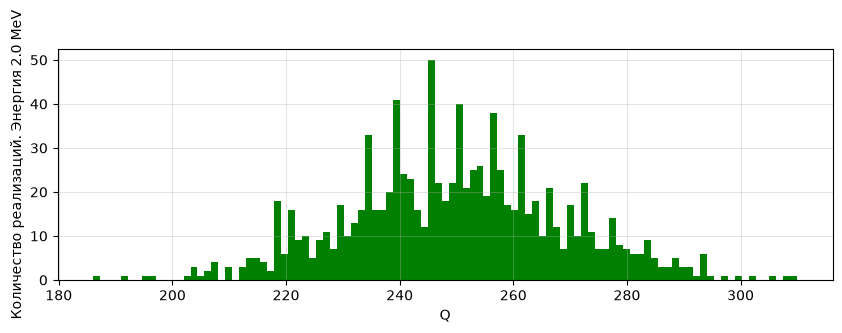

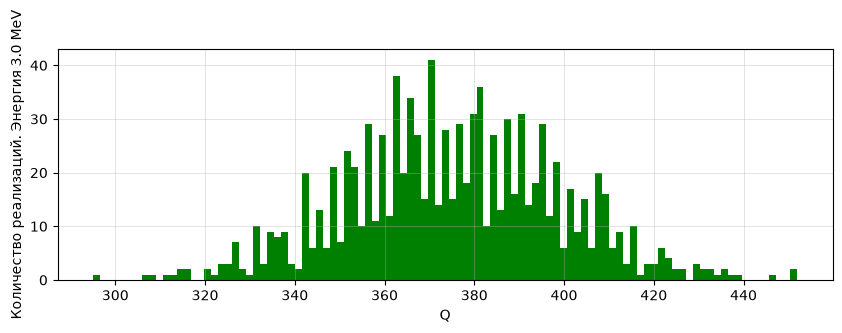

In [5]:
# отрисовка гистограмм
print(np.shape(Q_very_full))
for n, Q in enumerate(Q_very_full):
    plt.figure(figsize=(10, 3))
    plt.hist(Q, bins=101, color='green')
    plt.xlabel("Q")
    plt.ylabel(f"Количество реализаций. Энергия {energy_list[n]} MeV")
    plt.grid()
    plt.show()

Среднее значение энергии $<Q> = a p Y E \propto E$, $Var Q = a(1+a) pYE => \sigma \propto \sqrt E$

Тогда $\sigma / <Q> \propto 1/ \sqrt E$, то есть с ростом энергии относительная ширина убывает.

In [6]:
# посчитаем среднее по заряду для энергии 1.5 MeV
mean_1 = np.mean(Q_very_full[3])
print(mean_1)

188.616


In [7]:
# создаем смещенный источник
start_point_2 = np.array([0, 0, 1])
source_2 = Source(10**4, start_point_2)


In [8]:
# моделирование с разными энергиями 2
energy_list = [0.2, 0.5, 0.7, 1.5, 2.0, 3.0]

Q_very_full = [[] for _ in energy_list]
for n, E in enumerate(energy_list):
    for i in range(1000):
        photon_directions = source_2.generate_directions(E)  # создали фотоны
        cross_points = detector_1.find_cross_point(source_2.position, photon_directions)  # посчитали точки пересечения
        pm_points = detector_1.find_photomultiplier(cross_points)  # нашли нужные фэу
        hits = np.sum(pm_points != -1)  # посчитали попадания в фэу
        detections = detector_1.generate_photo_electrons(hits)  # собрали полный заряд
        Q_very_full[n].append(detections)

Q_very_full = np.array(Q_very_full)  # заворачиваем в массив


(6, 1000)


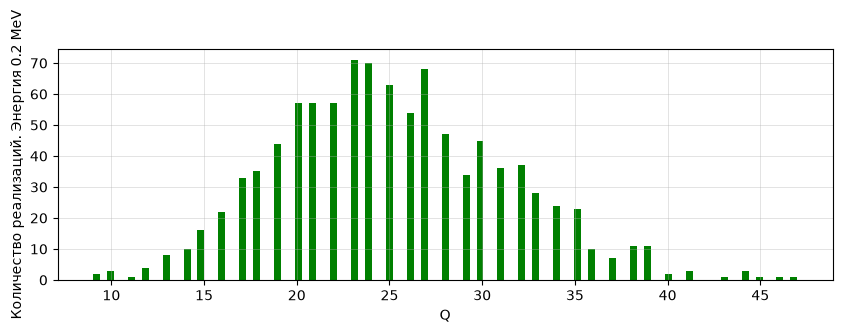

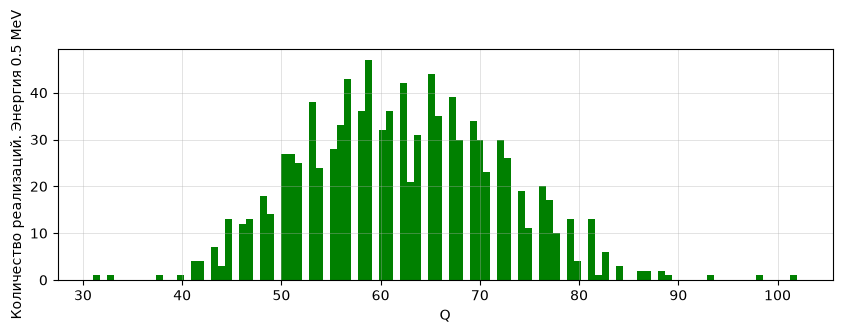

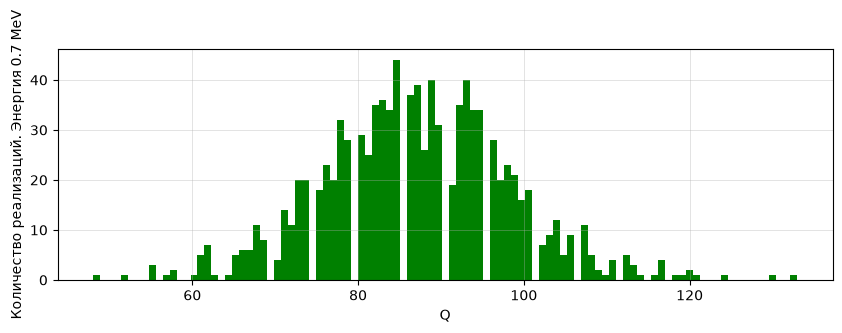

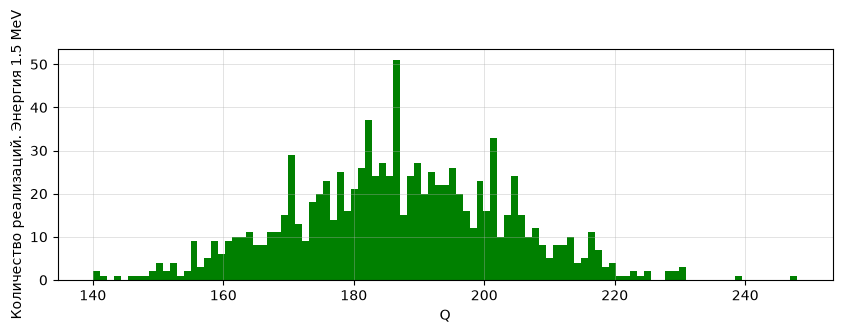

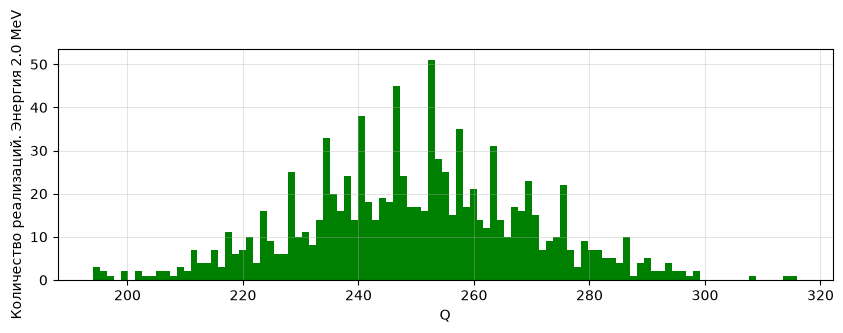

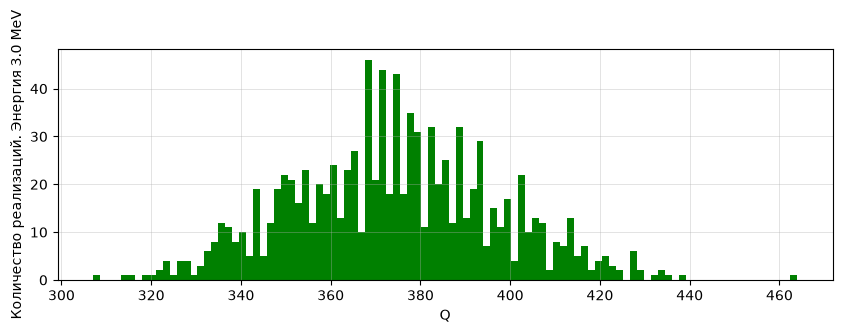

In [9]:
# отрисовка гистограмм 2
print(np.shape(Q_very_full))
for n, Q in enumerate(Q_very_full):
    plt.figure(figsize=(10, 3))
    plt.hist(Q, bins=101, color='green')
    plt.xlabel("Q")
    plt.ylabel(f"Количество реализаций. Энергия {energy_list[n]} MeV")
    plt.grid()
    plt.show()

In [11]:
# посчитаем теперь среднее для энергии 1.5 MeV
mean_2 = np.mean(Q_very_full[3])
print('Новое среднее:', mean_2)
print('Было:', mean_1,'Разница:',abs(mean_2 -mean_1))

Новое среднее: 186.93
Было: 188.616 Разница: 1.686000000000007


In [14]:
print(np.sqrt((1 + detector_1.probability_a)*mean_1))
print(17/np.sqrt(1000))
print(np.sqrt(2) * 0.53)

16.820344824051617
0.5375872022286245
0.7495331880577405


$\sigma = \sqrt{a(1+a)pYE}=\sqrt{(1+a) <Q>}$, при $E=1.5 MeV \approx 17$. Погрешность по 1000 событиям $17/\sqrt{1000} \approx 0.54.$  Тогда погрешность двух средних $\sqrt 2 \cdot 0.53 \approx 0.75$, то есть разница порядку двух $\sigma$ - незначительное отклонение.